In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = {
    'Student': [1,2,3,4,5,6,7,8,9,10],
    'Hours_Studied': [2,3,4,5,6,7,8,9,10,11],
    'Marks': [35,40,43,48,52,57,61,66,70,74]
}

df = pd.DataFrame(data)

print(df)

   Student  Hours_Studied  Marks
0        1              2     35
1        2              3     40
2        3              4     43
3        4              5     48
4        5              6     52
5        6              7     57
6        7              8     61
7        8              9     66
8        9             10     70
9       10             11     74


In [3]:
X = df[['Hours_Studied']]
y = df['Marks']

In [4]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

model = LinearRegression()

In [5]:
fold_results = []

fold_number = 1

for train_index, val_index in kf.split(X):

    X_train = X.iloc[train_index]
    X_val = X.iloc[val_index]

    y_train = y.iloc[train_index]
    y_val = y.iloc[val_index]

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    mse = mean_squared_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)

    fold_results.append({
        'Fold': fold_number,
        'Training Samples': len(X_train),
        'Validation Samples': len(X_val),
        'MSE': mse,
        'R2 Score': r2
    })

    fold_number += 1

results = pd.DataFrame(fold_results)

print(results)

   Fold  Training Samples  Validation Samples       MSE  R2 Score
0     1                 8                   2  0.400490  0.998220
1     2                 8                   2  0.034722  0.999713
2     3                 8                   2  0.500638  0.996214
3     4                 8                   2  0.211806  0.998250
4     5                 8                   2  0.017936  0.999575


In [6]:
print("Average MSE:", results['MSE'].mean())

print("Average R2 Score:", results['R2 Score'].mean())

print("Standard Deviation of MSE:", results['MSE'].std())

Average MSE: 0.23311848218544431
Average R2 Score: 0.9983945103983844
Standard Deviation of MSE: 0.215463801441714


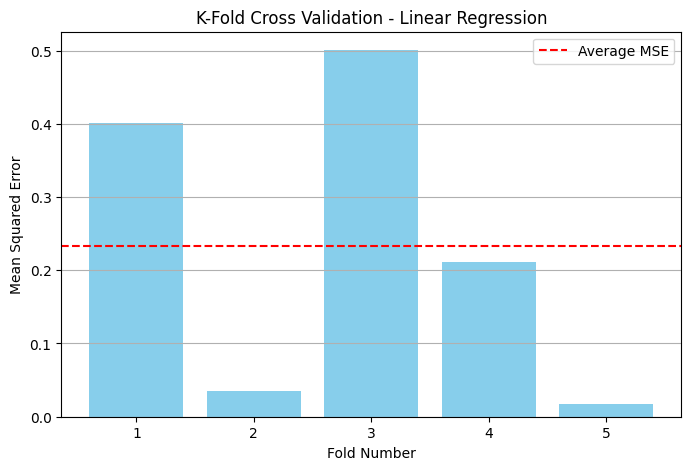

In [7]:
plt.figure(figsize=(8,5))

plt.bar(results['Fold'], results['MSE'], color='skyblue')

plt.axhline(
    results['MSE'].mean(),
    color='red',
    linestyle='--',
    label='Average MSE'
)

plt.xlabel('Fold Number')
plt.ylabel('Mean Squared Error')

plt.title('K-Fold Cross Validation - Linear Regression')

plt.legend()
plt.grid(axis='y')

plt.show()

In [8]:
final_model = LinearRegression()

final_model.fit(X, y)

y_pred = final_model.predict(X)

comparison = pd.DataFrame({
    'Actual Marks': y,
    'Predicted Marks': y_pred
})

print(comparison)

   Actual Marks  Predicted Marks
0            35        34.963636
1            40        39.327273
2            43        43.690909
3            48        48.054545
4            52        52.418182
5            57        56.781818
6            61        61.145455
7            66        65.509091
8            70        69.872727
9            74        74.236364


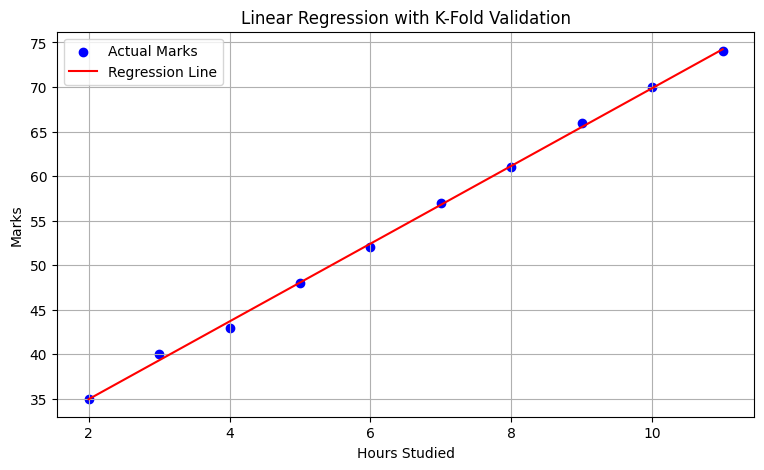

In [9]:
plt.figure(figsize=(9,5))

plt.scatter(X, y, color='blue', label='Actual Marks')

plt.plot(X, y_pred, color='red', label='Regression Line')

plt.xlabel('Hours Studied')
plt.ylabel('Marks')

plt.title('Linear Regression with K-Fold Validation')

plt.legend()
plt.grid()

plt.show()

In [10]:
print("K-FOLD CROSS VALIDATION RESULTS")

print("Number of Folds:", 5)

print("Average MSE:", round(results['MSE'].mean(), 3))

print("Average R2 Score:", round(results['R2 Score'].mean(), 3))

print("Final Intercept:", final_model.intercept_)

print("Final Coefficient:", final_model.coef_[0])

K-FOLD CROSS VALIDATION RESULTS
Number of Folds: 5
Average MSE: 0.233
Average R2 Score: 0.998
Final Intercept: 26.236363636363635
Final Coefficient: 4.363636363636364
